# Support Vector Machines

A complete guide: intuition, mathematics, and implementation from scratch.

**Prerequisites:** basic linear algebra, gradient descent (see `1_decision_tree.ipynb`, `2_random_forest.ipynb`)

## Table of Contents

1. [Why SVMs?](#why-svms)
2. [Geometry: Hyperplanes and Margins](#geometry)
3. [Setup & Imports](#imports)
4. [Hard-Margin SVM](#hard-margin)
   - [Maximal Margin Classifier](#maximal-margin)
   - [Lagrangian Dual & KKT Conditions](#dual)
   - [Linear SVM from Scratch](#linear-impl)
   - [Margin Visualization Demo](#margin-viz)
5. [Soft-Margin SVM (Slack Variables)](#soft-margin)
   - [Formulation with Slack Variables](#slack-formulation)
   - [The C Hyperparameter](#c-param)
   - [Visualizing the Effect of C](#c-effect)
6. [The Kernel Trick](#kernel-trick)
   - [Motivation: Non-linear Data](#nonlinear-motivation)
   - [Feature Maps](#feature-maps)
   - [Mercer's Theorem](#mercer)
7. [Kernel Functions](#kernels)
   - [Linear, Polynomial, RBF, Sigmoid](#kernel-functions)
   - [Kernel Matrix Visualization](#kernel-matrix)
8. [Kernelized SVM: Dual Formulation](#kernel-svm)
   - [Dual Problem with Kernels](#dual-problem)
   - [From-Scratch Implementation (QP)](#kernel-impl)
   - [Demo on Non-linear Data](#kernel-demo)
9. [Comparing Kernels](#kernel-comparison)
10. [Hyperparameter Tuning (C and \u03b3)](#hyperparams)
11. [SVM for Regression (SVR)](#svr)
12. [Multi-class SVM](#multiclass)
    - [One-vs-One (OvO)](#ovo)
    - [One-vs-Rest (OvR)](#ovr)
    - [Multi-class Demo](#multiclass-demo)
13. [Pros and Cons](#pros-cons)
14. [Summary](#summary)
15. [Sources](#sources)

<a id="why-svms"></a>
## 1. Why SVMs? The Key Idea

Consider a binary classification problem with linearly separable data. There are **infinitely many** hyperplanes that perfectly separate the two classes.

**Key question:** which separating hyperplane is best?

**SVM's answer:** the one that maximizes the **margin** — the distance between the hyperplane and the nearest training points from either class.

### Intuition: Why Maximize the Margin?

A large margin means the classifier is far from all training points, giving more "breathing room" for unseen test data:
- A classifier barely touching training points will likely misclassify nearby test points.
- A classifier maximally far from all training points generalizes better.

This intuition is backed by statistical learning theory: Vapnik & Chervonenkis showed that the **generalization error bound** depends on the margin. Larger margin → tighter bound → better expected test performance.

### Two Core Versions

| Version | Training Data | Key Idea |
|---|---|---|
| **Hard-margin SVM** | Linearly separable | No misclassification allowed |
| **Soft-margin SVM** | Any (possibly non-separable) | Misclassifications penalized by constant $C$ |

And with the **kernel trick**, SVMs can learn non-linear boundaries by implicitly mapping data to a higher-dimensional space.

<a id="geometry"></a>
## 2. Geometry: Hyperplanes and Margins

### Hyperplanes

A **hyperplane** in $\mathbb{R}^p$ is defined by:

$$\mathcal{H} = \{x \in \mathbb{R}^p : w^\top x + b = 0\}$$

where $w \in \mathbb{R}^p$ is the **normal vector** and $b \in \mathbb{R}$ is the **bias**.

The sign of $w^\top x + b$ tells which side of the hyperplane $x$ lies on:
- $w^\top x + b > 0$: positive side (class $+1$)
- $w^\top x + b < 0$: negative side (class $-1$)

### Signed Distance from a Point to the Hyperplane

$$d(x) = \frac{w^\top x + b}{\|w\|}$$

### Functional and Geometric Margin

For training point $(x_i, y_i)$ with $y_i \in \{-1, +1\}$:

- **Functional margin:** $\hat{\gamma}_i = y_i (w^\top x_i + b)$
- **Geometric margin (actual distance):** $\gamma_i = \dfrac{y_i(w^\top x_i + b)}{\|w\|}$

The **margin of the classifier** is the minimum over all training points (assuming all are correctly classified):

$$\gamma = \min_i \, \gamma_i = \frac{\min_i \, y_i(w^\top x_i + b)}{\|w\|}$$

**Support vectors** are the points that achieve this minimum — the points closest to the decision boundary. They are the *only* training points that determine the hyperplane.

### Canonical Scaling

We can always scale $w$ and $b$ so that the support vectors satisfy:

$$y_i(w^\top x_i + b) = 1 \quad \text{(on the margin hyperplane)}$$

Then the two margin hyperplanes are $w^\top x + b = +1$ and $w^\top x + b = -1$, and the **total margin width** is:

$$\text{margin} = \frac{2}{\|w\|}

<a id="imports"></a>
## 3. Setup & Imports

All libraries used throughout this notebook: NumPy and Matplotlib for numerics and visualization, SciPy for the dual QP solver, and scikit-learn for datasets and reference implementations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from itertools import combinations
from sklearn.datasets import (make_blobs, make_classification,
                               make_moons, make_circles, load_iris)
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC, SVR
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
print("Imports OK")

Imports OK


<a id="hard-margin"></a>
## 4. Hard-Margin SVM

<a id="maximal-margin"></a>
### 4.1 Maximal Margin Classifier

For **linearly separable** data with labels $y_i \in \{-1, +1\}$, we want the hyperplane that correctly classifies all points **and** maximizes the margin.

Using the canonical scaling ($y_i(w^\top x_i + b) \geq 1$ for all $i$), maximizing the margin $2/\|w\|$ is equivalent to minimizing $\|w\|^2$:

$$\min_{w,\,b} \; \frac{1}{2}\|w\|^2 \quad \text{subject to} \quad y_i(w^\top x_i + b) \geq 1 \quad \forall\, i = 1,\ldots,n$$

This is a **quadratic programming (QP)** problem: quadratic objective, linear inequality constraints, unique global minimum (strictly convex).

<a id="dual"></a>
### 4.2 Lagrangian Dual & KKT Conditions

Introduce Lagrange multipliers $\alpha_i \geq 0$ for each constraint:

$$\mathcal{L}(w, b, \alpha) = \frac{1}{2}\|w\|^2 - \sum_{i=1}^n \alpha_i \bigl[y_i(w^\top x_i + b) - 1\bigr]$$

**KKT conditions** (necessary and sufficient for this convex QP):

1. $\nabla_w \mathcal{L} = 0 \implies w = \displaystyle\sum_i \alpha_i y_i x_i$
2. $\nabla_b \mathcal{L} = 0 \implies \displaystyle\sum_i \alpha_i y_i = 0$
3. **Complementary slackness:** $\alpha_i \bigl[y_i(w^\top x_i + b) - 1\bigr] = 0$

**Key insight from condition 3:** $\alpha_i > 0$ **only when** $y_i(w^\top x_i + b) = 1$ — only for **support vectors**. All other $\alpha_i = 0$, so only support vectors determine $w$.

Substituting condition 1 into $\mathcal{L}$ and maximizing over $\alpha$ gives the **dual problem**:

$$\max_\alpha \; \sum_i \alpha_i - \frac{1}{2}\sum_{i,j} \alpha_i \alpha_j y_i y_j \, x_i^\top x_j$$
$$\text{subject to:} \quad \sum_i \alpha_i y_i = 0, \quad \alpha_i \geq 0$$

The dual depends on training points only through inner products $x_i^\top x_j$ — this is exactly what the kernel trick replaces with $K(x_i, x_j)$.

**Prediction** using the dual solution:

$$\hat{y}(x) = \text{sign}\!\left(\sum_i \alpha_i y_i \, x_i^\top x + b\right)$$

<a id="linear-impl"></a>
### 4.3 Linear SVM — Primal Subgradient Implementation

Implement `LinearSVM` using full-batch subgradient descent on the primal objective:

$$\min_{w,\,b} \; \frac{1}{2}\|w\|^2 + C\sum_{i=1}^n \max\!\bigl(0,\, 1 - y_i(w^\top x_i + b)\bigr)$$

The subgradient for a sample $i$ where $y_i(w^\top x_i + b) < 1$ (margin violated):
- w.r.t. $w$: $w - C\, y_i\, x_i$
- w.r.t. $b$: $-C\, y_i$

This is the **Pegasos** approach (Shalev-Shwartz et al., 2007). The same class handles both hard-margin (large $C$) and soft-margin (finite $C$) by tuning the penalty.

In [2]:
class LinearSVM:
    # Minimizes: (1/2)||w||^2 + C * sum(max(0, 1 - y_i(w·x_i + b)))
    # C: regularization strength  |  lr: learning rate  |  n_epochs: epochs

    def __init__(self, C=1.0, lr=0.001, n_epochs=1000):
        self.C        = C
        self.lr       = lr
        self.n_epochs = n_epochs

    def fit(self, X, y):
        n, p = X.shape
        self.classes_ = np.unique(y)
        y_ = np.where(y == self.classes_[1], 1.0, -1.0)

        self.w_      = np.zeros(p)
        self.b_      = 0.0
        self.losses_ = []

        for _ in range(self.n_epochs):
            margins = y_ * (X @ self.w_ + self.b_)
            mask    = margins < 1  # samples violating the margin

            dw = self.w_ - self.C * (y_[mask, None] * X[mask]).sum(axis=0)
            db = -self.C * y_[mask].sum()

            self.w_ -= self.lr * dw
            self.b_ -= self.lr * db

            hinge = np.maximum(0, 1 - margins).sum()
            self.losses_.append(0.5 * self.w_ @ self.w_ + self.C * hinge)

        return self

    def decision_function(self, X):
        return X @ self.w_ + self.b_

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0,
                        self.classes_[1], self.classes_[0])


print("LinearSVM defined.")

LinearSVM defined.


<a id="margin-viz"></a>
### 4.4 Margin Visualization Demo

Generate a linearly separable 2D dataset, train `LinearSVM`, plot the training loss curve, compare test accuracy against sklearn's `SVC(kernel='linear')`, and visualize the decision boundary with margin hyperplanes and support vectors.

Our LinearSVM  — test accuracy: 1.0000
sklearn SVC    — test accuracy: 1.0000


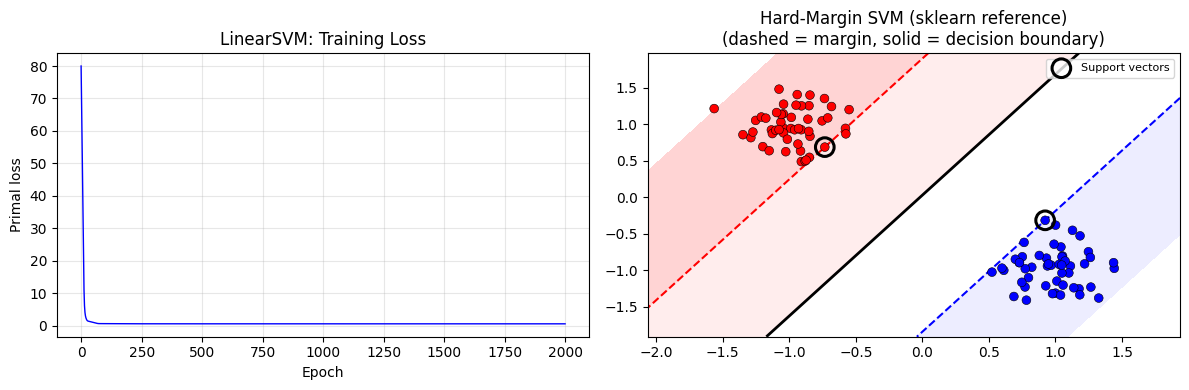

Margin width = 2/||w|| = 1.9349
Number of support vectors: 2


In [3]:
# ── Helper: plot decision boundary and margin lines ──────────────────────
def plot_svm_boundary(clf, X, y, ax=None, title='SVM', support_vecs=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))
    h = 0.02
    x0_min, x0_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x1_min, x1_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x0_min, x0_max, h),
                          np.arange(x1_min, x1_max, h))
    Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-2, -1, 0, 1, 2],
                colors=['#FFAAAA','#FFDDDD','#FFFFFF','#DDDDFF','#AAAAFF'], alpha=0.5)
    ax.contour(xx, yy, Z, levels=[-1, 0, 1],
               linestyles=['--', '-', '--'], colors=['red', 'black', 'blue'],
               linewidths=[1.5, 2, 1.5])
    ax.scatter(X[:, 0], X[:, 1],
               c=np.where(y == np.unique(y)[1], 'blue', 'red'),
               s=40, edgecolors='k', linewidth=0.4, zorder=3)
    if support_vecs is not None:
        ax.scatter(support_vecs[:, 0], support_vecs[:, 1],
                   s=180, facecolors='none', edgecolors='black',
                   linewidths=2.2, zorder=4, label='Support vectors')
        ax.legend(fontsize=8)
    ax.set_title(title)
    return ax


# ── Generate separable data ───────────────────────────────────────────────
X_sep, y_sep = make_blobs(n_samples=100, centers=2, cluster_std=0.9, random_state=42)
y_sep = np.where(y_sep == 0, -1, 1)
scaler0 = StandardScaler()
X_sep = scaler0.fit_transform(X_sep)

X_tr0, X_te0, y_tr0, y_te0 = train_test_split(X_sep, y_sep, test_size=0.2, random_state=42)

# ── Train our LinearSVM ───────────────────────────────────────────────────
lsvm = LinearSVM(C=1.0, lr=5e-4, n_epochs=2000)
lsvm.fit(X_tr0, y_tr0)
print(f"Our LinearSVM  — test accuracy: {accuracy_score(y_te0, lsvm.predict(X_te0)):.4f}")

# sklearn reference
sk0 = SVC(kernel='linear', C=1.0)
sk0.fit(X_tr0, y_tr0)
print(f"sklearn SVC    — test accuracy: {accuracy_score(y_te0, sk0.predict(X_te0)):.4f}")

# ── Loss curve ────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(lsvm.losses_, 'b-', linewidth=1)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Primal loss')
axes[0].set_title('LinearSVM: Training Loss')
axes[0].grid(True, alpha=0.3)

plot_svm_boundary(sk0, X_sep, y_sep, ax=axes[1],
                  title='Hard-Margin SVM (sklearn reference)\n(dashed = margin, solid = decision boundary)',
                  support_vecs=sk0.support_vectors_)
plt.tight_layout()
plt.show()

margin_width = 2 / np.linalg.norm(sk0.coef_)
print(f"Margin width = 2/||w|| = {margin_width:.4f}")
print(f"Number of support vectors: {len(sk0.support_vectors_)}")

<a id="soft-margin"></a>
## 5. Soft-Margin SVM (Slack Variables)

<a id="slack-formulation"></a>
### 5.1 Formulation with Slack Variables

Hard-margin SVM fails when data is not linearly separable. **Slack variables** $\xi_i \geq 0$ allow each training point to violate the margin constraint by up to $\xi_i$:

$$y_i(w^\top x_i + b) \geq 1 - \xi_i \quad \forall\, i$$

Interpretation:
- $\xi_i = 0$: correctly classified with sufficient margin
- $0 < \xi_i \leq 1$: inside the margin but on the correct side
- $\xi_i > 1$: misclassified

**Modified primal problem:**

$$\min_{w,\,b,\,\xi} \; \frac{1}{2}\|w\|^2 + C\sum_{i=1}^n \xi_i \quad \text{subject to} \quad y_i(w^\top x_i + b) \geq 1 - \xi_i, \quad \xi_i \geq 0$$

At the optimum, $\xi_i = \max(0,\, 1 - y_i(w^\top x_i + b))$ — the **hinge loss** — so the objective is equivalent to:

$$\min_{w,\,b} \; \frac{1}{2}\|w\|^2 + C\sum_i \max\!\bigl(0,\, 1 - y_i(w^\top x_i + b)\bigr)$$

This is exactly what `LinearSVM` minimizes. The class already implements soft-margin SVM.

The dual gains a box constraint on $\alpha_i$:

$$0 \leq \alpha_i \leq C \quad \forall\, i$$

<a id="c-param"></a>
### 5.2 The C Hyperparameter

| C value | Effect |
|---|---|
| **Large C** | Heavy penalty on violations → small margin, fewer misclassifications → may overfit |
| **Small C** | Tolerates violations → wide margin, more misclassifications → better regularization |

$C$ controls the bias-variance tradeoff. It is selected via cross-validation.

<a id="c-effect"></a>
### 5.3 Visualizing the Effect of C

Fit sklearn `SVC(kernel='linear')` with five values of $C$ on a noisy, overlapping dataset. Plot each decision boundary side-by-side, showing how $C$ trades off margin width against the number of support vectors and violations.

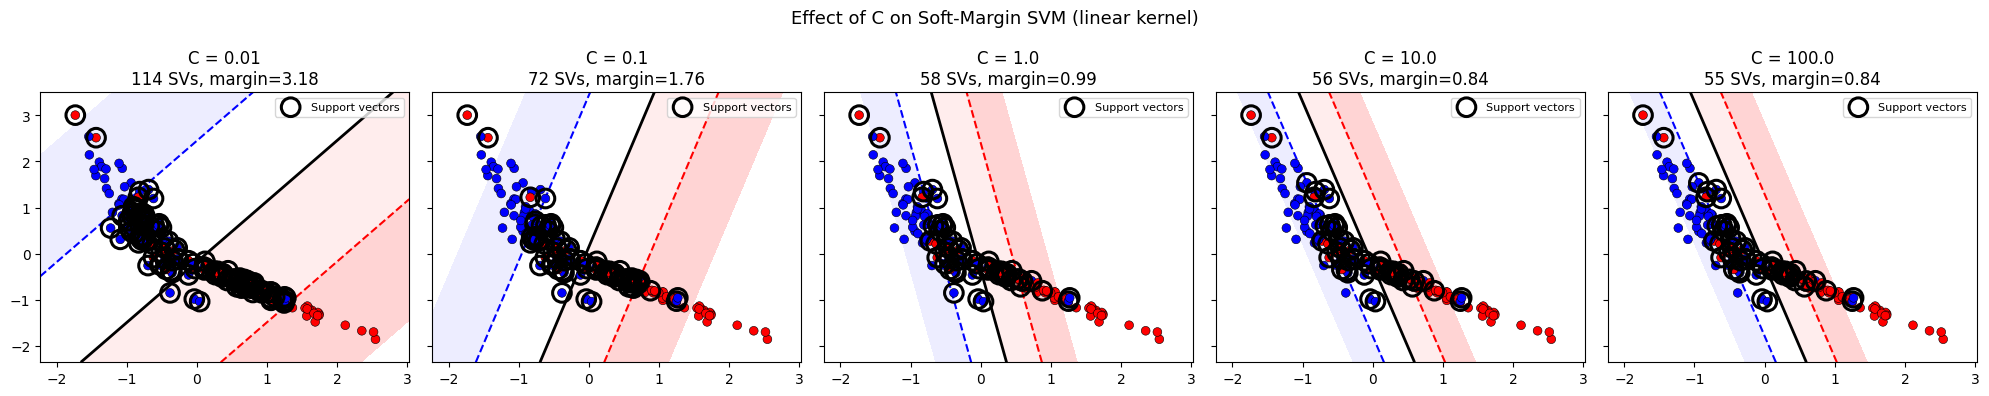

In [4]:
X_noisy, y_noisy = make_classification(n_samples=150, n_features=2,
                                        n_informative=2, n_redundant=0,
                                        n_clusters_per_class=1,
                                        flip_y=0.12, random_state=7)
y_noisy = np.where(y_noisy == 0, -1, 1)
scaler1 = StandardScaler()
X_noisy = scaler1.fit_transform(X_noisy)

C_values = [0.01, 0.1, 1.0, 10.0, 100.0]
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

for ax, C in zip(axes, C_values):
    clf = SVC(kernel='linear', C=C)
    clf.fit(X_noisy, y_noisy)
    margin = 2 / np.linalg.norm(clf.coef_)
    plot_svm_boundary(clf, X_noisy, y_noisy, ax=ax,
                      title=f'C = {C}\n{len(clf.support_vectors_)} SVs, margin={margin:.2f}',
                      support_vecs=clf.support_vectors_)

plt.suptitle('Effect of C on Soft-Margin SVM (linear kernel)', fontsize=13)
plt.tight_layout()
plt.show()

<a id="kernel-trick"></a>
## 6. The Kernel Trick

<a id="nonlinear-motivation"></a>
### 6.1 Motivation: Non-linear Data

Linear SVMs fail on non-linearly separable data (e.g., XOR, concentric circles).

**Solution idea:** map data to a higher-dimensional space where it becomes linearly separable, then apply a linear SVM there.

<a id="feature-maps"></a>
### 6.2 Feature Maps

A **feature map** $\phi: \mathbb{R}^p \to \mathcal{F}$ transforms inputs to a (possibly infinite-dimensional) feature space.

**Example — XOR:** Add the cross-term feature $x_1 x_2$:
$$\phi(x_1, x_2) = (x_1,\; x_2,\; x_1 x_2)$$

In this 3D space, the XOR pattern becomes linearly separable at the plane $x_1 x_2 = 0$.

**Problem:** for large or infinite $\dim(\mathcal{F})$, explicitly computing $\phi(x)$ is intractable.

**The Kernel Trick:** the SVM dual only needs inner products $\langle \phi(x_i), \phi(x_j) \rangle$. If we define:

$$K(x_i, x_j) = \langle \phi(x_i), \phi(x_j) \rangle$$

we can compute this inner product **without materializing $\phi$**. We simply replace $x_i^\top x_j$ with $K(x_i, x_j)$ everywhere in the dual.

<a id="mercer"></a>
### 6.3 Mercer's Theorem

Not every function $K$ corresponds to an inner product in some feature space. The condition:

> A symmetric function $K: \mathbb{R}^p \times \mathbb{R}^p \to \mathbb{R}$ is a valid (Mercer) kernel if and only if the kernel matrix $K_{ij} = K(x_i, x_j)$ is **positive semi-definite (PSD)** for any finite set of inputs.

PSD means $\sum_{i,j} c_i c_j K(x_i, x_j) \geq 0$ for all $c \in \mathbb{R}^n$.

**Closure properties:** sums, products, and positive scalings of valid kernels are also valid kernels.

Generate an XOR dataset (not linearly separable in 2D), then add the cross-term $x_1 x_2$ as a third feature. Show that the transformed data is linearly separable — the separating hyperplane is exactly $x_1 x_2 = 0$.

<>:14: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\p'
<>:23: SyntaxWarning: invalid escape sequence '\,'
<>:14: SyntaxWarning: invalid escape sequence '\m'
<>:22: SyntaxWarning: invalid escape sequence '\p'
<>:23: SyntaxWarning: invalid escape sequence '\,'
/tmp/ipykernel_608381/2113122804.py:14: SyntaxWarning: invalid escape sequence '\m'
  ax.set_title('XOR in Original $\mathbb{R}^2$ — Not Linearly Separable')
/tmp/ipykernel_608381/2113122804.py:22: SyntaxWarning: invalid escape sequence '\p'
  ax.set_title('After Feature Map $\phi(x_1,x_2) = (x_1,\, x_2,\, x_1 x_2)$\n'
/tmp/ipykernel_608381/2113122804.py:23: SyntaxWarning: invalid escape sequence '\,'
  'Projection onto $(x_1,\, x_1 x_2)$')


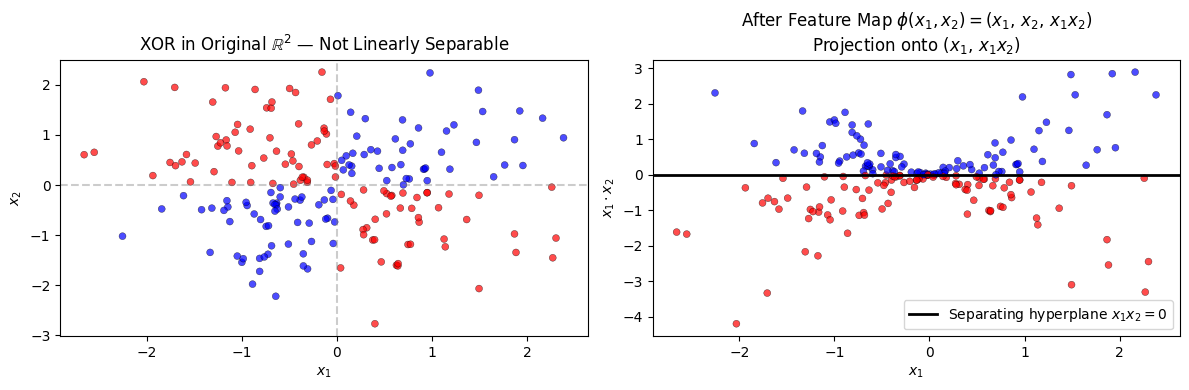

Adding x1*x2 as a feature makes XOR linearly separable!


In [5]:
np.random.seed(0)
X_xor = np.random.randn(200, 2)
y_xor = np.where(X_xor[:, 0] * X_xor[:, 1] > 0, 1, -1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

colors = np.where(y_xor == 1, 'blue', 'red')

# Original 2D space — not separable
ax = axes[0]
ax.scatter(X_xor[:, 0], X_xor[:, 1], c=colors, s=25, alpha=0.7, edgecolors='k', lw=0.3)
ax.axhline(0, color='gray', linestyle='--', alpha=0.4)
ax.axvline(0, color='gray', linestyle='--', alpha=0.4)
ax.set_title('XOR in Original $\mathbb{R}^2$ — Not Linearly Separable')
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_2$')

# Transformed space — separable at x1*x2 = 0
ax = axes[1]
x3 = X_xor[:, 0] * X_xor[:, 1]   # new feature
ax.scatter(X_xor[:, 0], x3, c=colors, s=25, alpha=0.7, edgecolors='k', lw=0.3)
ax.axhline(0, color='black', linewidth=2, label='Separating hyperplane $x_1 x_2 = 0$')
ax.set_title('After Feature Map $\phi(x_1,x_2) = (x_1,\, x_2,\, x_1 x_2)$\n'
             'Projection onto $(x_1,\, x_1 x_2)$')
ax.set_xlabel('$x_1$'); ax.set_ylabel('$x_1 \\cdot x_2$')
ax.legend()

plt.tight_layout()
plt.show()
print("Adding x1*x2 as a feature makes XOR linearly separable!")

<a id="kernels"></a>
## 7. Kernel Functions

<a id="kernel-functions"></a>
### 7.1 The Four Standard Kernels

| Kernel | Formula | Feature space |
|---|---|---|
| **Linear** | $K(x,z) = x^\top z$ | Original space ($\phi = \text{id}$) |
| **Polynomial** | $K(x,z) = (\gamma\, x^\top z + r)^d$ | All monomials up to degree $d$ |
| **RBF (Gaussian)** | $K(x,z) = \exp(-\gamma\|x-z\|^2)$ | Infinite-dimensional (RKHS) |
| **Sigmoid** | $K(x,z) = \tanh(\gamma\, x^\top z + r)$ | Neural-network-like (not always PSD) |

**RBF kernel intuition:** $K(x,z)$ measures similarity — it equals 1 when $x = z$ and decays to 0 as they become distant. $\gamma$ controls how quickly it decays:
- Small $\gamma$: wide influence, smooth boundary
- Large $\gamma$: narrow influence, complex/wiggly boundary

**Polynomial kernel:** $d$ controls the degree of non-linearity. $r$ (coef0) controls the relative weight of low-order vs. high-order terms.

Implement all four kernel functions as standalone NumPy functions that accept two matrices $X_1$ and $X_2$ and return the kernel matrix $K$ of shape $(|X_1|, |X_2|)$. Verify symmetry on a small random dataset.

In [ ]:
def linear_kernel(X1, X2):
    return X1 @ X2.T


def poly_kernel(X1, X2, degree=3, gamma=1.0, coef0=1.0):
    return (gamma * X1 @ X2.T + coef0) ** degree


def rbf_kernel(X1, X2, gamma=1.0):
    # Efficient pairwise squared distances: ||x-z||^2 = ||x||^2 - 2x^Tz + ||z||^2
    # Clamp to 0 to prevent tiny negative values from floating-point cancellation
    sq_dists = (np.sum(X1 ** 2, axis=1, keepdims=True)
                - 2 * X1 @ X2.T
                + np.sum(X2 ** 2, axis=1))
    return np.exp(-gamma * np.maximum(sq_dists, 0.0))


def sigmoid_kernel(X1, X2, gamma=1.0, coef0=0.0):
    return np.tanh(gamma * X1 @ X2.T + coef0)


# Verify symmetry on small random data
X_check = np.random.randn(8, 3)
for name, K in [('linear',  linear_kernel(X_check, X_check)),
                ('poly',    poly_kernel(X_check, X_check)),
                ('rbf',     rbf_kernel(X_check, X_check)),
                ('sigmoid', sigmoid_kernel(X_check, X_check))]:
    print(f"  {name:8s}: symmetric = {np.allclose(K, K.T)},  "
          f"min eigenvalue = {np.linalg.eigvalsh(K).min():.4f}")

<a id="kernel-matrix"></a>
### 7.2 Kernel Matrix Visualization

Plot the $n \times n$ kernel matrix $K_{ij} = K(x_i, x_j)$ for a dataset sorted by class. A good kernel shows high values within the same class (diagonal blocks) and low values across classes (off-diagonal blocks).

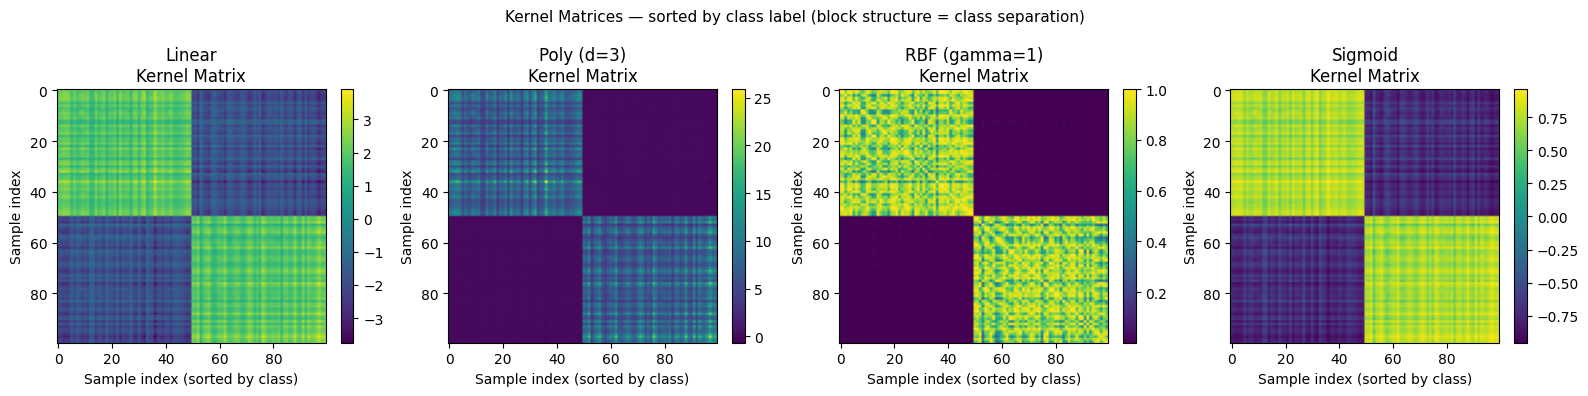

In [7]:
sort_idx = np.argsort(y_sep)
X_sorted = X_sep[sort_idx]

kernels_to_plot = {
    'Linear':       linear_kernel(X_sorted, X_sorted),
    'Poly (d=3)':   poly_kernel(X_sorted, X_sorted, degree=3, gamma=0.5),
    'RBF (gamma=1)':rbf_kernel(X_sorted, X_sorted, gamma=1.0),
    'Sigmoid':      sigmoid_kernel(X_sorted, X_sorted, gamma=0.5),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (name, K) in zip(axes, kernels_to_plot.items()):
    im = ax.imshow(K, cmap='viridis', aspect='auto')
    ax.set_title(f'{name}\nKernel Matrix')
    ax.set_xlabel('Sample index (sorted by class)')
    ax.set_ylabel('Sample index')
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.suptitle('Kernel Matrices — sorted by class label (block structure = class separation)',
             fontsize=11)
plt.tight_layout()
plt.show()

<a id="kernel-svm"></a>
## 8. Kernelized SVM: Dual Formulation

<a id="dual-problem"></a>
### 8.1 Dual Problem with Kernels

Replace $x_i^\top x_j$ with $K(x_i, x_j)$ in the dual. The **soft-margin kernelized SVM dual** is:

$$\max_\alpha \; \sum_i \alpha_i - \frac{1}{2}\sum_{i,j} \alpha_i \alpha_j y_i y_j K(x_i, x_j)$$
$$\text{subject to:} \quad \sum_i \alpha_i y_i = 0, \quad 0 \leq \alpha_i \leq C$$

Equivalently, minimizing $f(\alpha) = \frac{1}{2}\alpha^\top Q\, \alpha - \mathbf{1}^\top \alpha$ where $Q_{ij} = y_i y_j K(x_i, x_j)$.

**Decision function** (using only support vectors where $\alpha_i > 0$):

$$f(x) = \sum_{i \,:\, \alpha_i > 0} \alpha_i y_i K(x_i, x) + b$$

**Bias $b$:** computed from margin support vectors ($0 < \alpha_i < C$, on the margin hyperplane):

$$b = y_s - \sum_i \alpha_i y_i K(x_i, x_s) \quad \text{averaged over all such support vectors } s$$

### Brief Note on SMO

Directly solving the QP is $O(n^3)$. **Sequential Minimal Optimization (SMO)** (Platt, 1998) decomposes it into minimal two-variable sub-problems solvable analytically, achieving roughly $O(n^2)$ in practice. It is the algorithm behind libsvm and sklearn's `SVC`.

<a id="kernel-impl"></a>
### 8.2 From-Scratch KernelSVM Implementation

Implement `KernelSVM`: solve the dual QP with `scipy.optimize.minimize` (method `SLSQP`), extract support vectors from $\alpha_i > 0$, compute bias $b$ from margin support vectors, and implement `decision_function` and `predict`.

In [8]:
class KernelSVM:
    # Kernelized SVM (binary) — dual QP via scipy.optimize SLSQP.
    # C: box constraint  |  kernel: 'linear'|'poly'|'rbf'|'sigmoid'
    # degree/gamma/coef0: kernel params  |  tol: support-vector threshold

    def __init__(self, C=1.0, kernel='rbf', degree=3,
                 gamma='scale', coef0=1.0, tol=1e-4):
        self.C      = C
        self.kernel = kernel
        self.degree = degree
        self.gamma  = gamma
        self.coef0  = coef0
        self.tol    = tol

    def _resolve_gamma(self, X):
        if self.gamma == 'scale':
            v = X.var()
            return 1.0 / (X.shape[1] * v) if v > 0 else 1.0
        if self.gamma == 'auto':
            return 1.0 / X.shape[1]
        return float(self.gamma)

    def _K(self, X1, X2):
        g = self._g
        if self.kernel == 'linear':
            return linear_kernel(X1, X2)
        if self.kernel == 'poly':
            return poly_kernel(X1, X2, self.degree, g, self.coef0)
        if self.kernel == 'rbf':
            return rbf_kernel(X1, X2, g)
        if self.kernel == 'sigmoid':
            return sigmoid_kernel(X1, X2, g, self.coef0)
        raise ValueError(f"Unknown kernel: {self.kernel}")

    def fit(self, X, y):
        n = len(y)
        self.classes_ = np.unique(y)
        y_ = np.where(y == self.classes_[1], 1.0, -1.0)
        self._g = self._resolve_gamma(X)

        Q = np.outer(y_, y_) * self._K(X, X)   # Q_ij = y_i y_j K(xi, xj)

        def objective(a):
            return 0.5 * a @ Q @ a - a.sum()

        def jacobian(a):
            return Q @ a - np.ones(n)

        result = minimize(
            objective, np.zeros(n), jac=jacobian, method='SLSQP',
            bounds=[(0.0, self.C)] * n,
            constraints={'type': 'eq', 'fun': lambda a: a @ y_, 'jac': lambda _: y_},
            options={'maxiter': 500, 'ftol': 1e-9}
        )

        alpha = result.x
        alpha[alpha < self.tol] = 0.0

        sv          = alpha > self.tol
        self._alpha = alpha[sv]
        self._sv_X  = X[sv]
        self._sv_y  = y_[sv]
        # keep full alpha for efficient decision_function
        self._alpha_full = alpha
        self._y_full     = y_
        self._X_train    = X

        # bias: average over support vectors strictly inside box (0 < alpha < C)
        margin_sv = sv & (alpha < self.C - self.tol)
        if margin_sv.sum() == 0:
            margin_sv = sv
        scores = (alpha * y_) @ self._K(X[margin_sv], X).T
        self.b_ = np.mean(y_[margin_sv] - scores)

        return self

    def decision_function(self, X):
        return (self._alpha_full * self._y_full) @ self._K(self._X_train, X) + self.b_

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0,
                        self.classes_[1], self.classes_[0])


print("KernelSVM defined.")

KernelSVM defined.


<a id="kernel-demo"></a>
### 8.3 Demo on Non-linear Data

Test `KernelSVM(kernel='rbf')` on `make_moons` and `make_circles` — datasets that are not linearly separable. Compare decision boundaries and accuracy against sklearn's `SVC`.

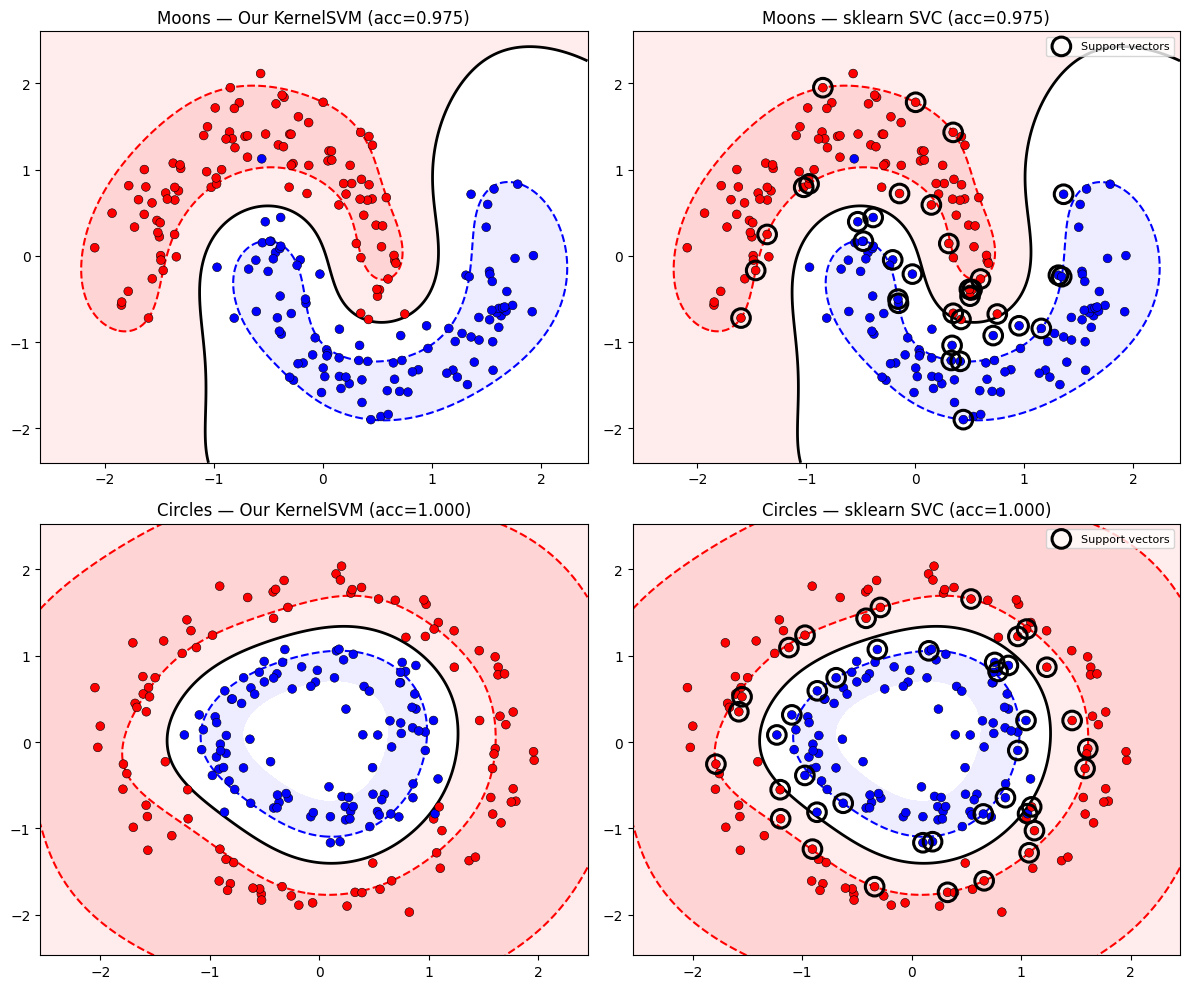

In [10]:
datasets = {
    'Moons':   make_moons(n_samples=200, noise=0.15, random_state=42),
    'Circles': make_circles(n_samples=200, noise=0.1, factor=0.5, random_state=42),
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for row, (name, (Xd, yd)) in enumerate(datasets.items()):
    yd_pm = np.where(yd == 0, -1, 1)
    sc = StandardScaler()
    Xd_s = sc.fit_transform(Xd)
    Xtr, Xte, ytr, yte = train_test_split(Xd_s, yd_pm, test_size=0.2, random_state=42)

    ksvm = KernelSVM(C=1.0, kernel='rbf', gamma=1.0)
    ksvm.fit(Xtr, ytr)
    our_acc = accuracy_score(yte, ksvm.predict(Xte))

    sk_clf = SVC(kernel='rbf', C=1.0, gamma=1.0)
    sk_clf.fit(Xtr, ytr)
    sk_acc = accuracy_score(yte, sk_clf.predict(Xte))

    plot_svm_boundary(ksvm, Xd_s, yd_pm, ax=axes[row, 0],
                      title=f'{name} — Our KernelSVM (acc={our_acc:.3f})')
    plot_svm_boundary(sk_clf, Xd_s, yd_pm, ax=axes[row, 1],
                      title=f'{name} — sklearn SVC (acc={sk_acc:.3f})',
                      support_vecs=sk_clf.support_vectors_)

plt.tight_layout()
plt.show()

<a id="kernel-comparison"></a>
## 9. Comparing Kernels

Fit sklearn `SVC` with four kernel configurations on `make_moons` and plot the decision boundaries side-by-side. This illustrates how kernel choice and $\gamma$ together shape the boundary: linear fails on non-linear data; polynomial is intermediate; RBF with large $\gamma$ becomes excessively local.

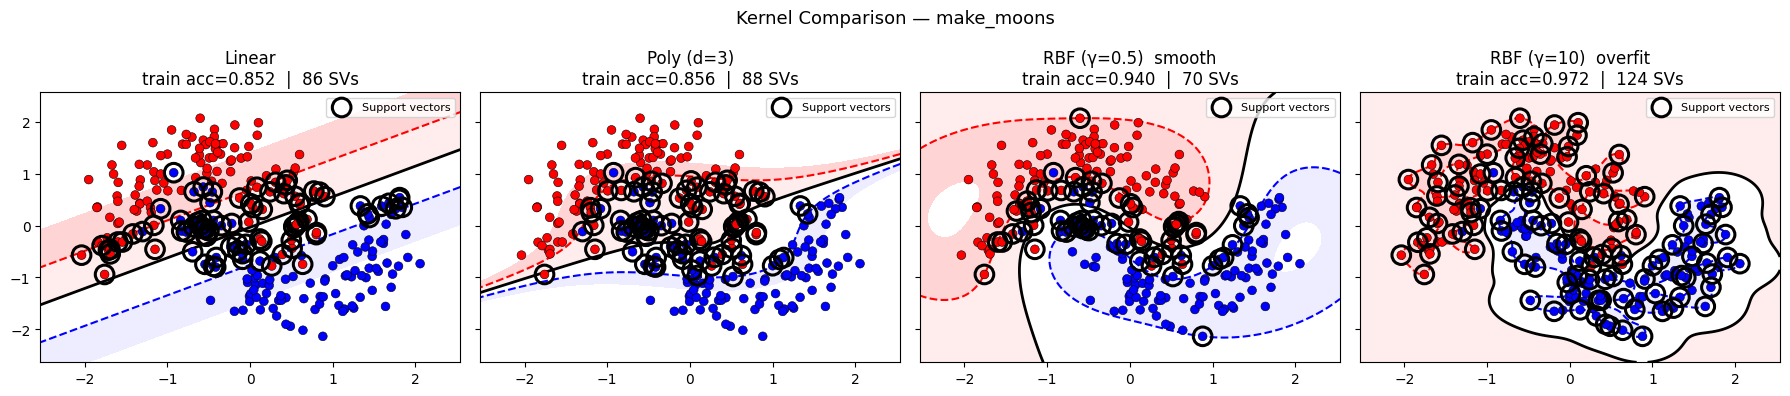

In [11]:
X_moon, y_moon = make_moons(n_samples=250, noise=0.2, random_state=42)
y_moon_pm = np.where(y_moon == 0, -1, 1)
sc_m = StandardScaler()
X_moon_s = sc_m.fit_transform(X_moon)

configs = [
    ('linear',  {'C': 1.0},               'Linear'),
    ('poly',    {'C': 1.0, 'degree': 3},   'Poly (d=3)'),
    ('rbf',     {'C': 1.0, 'gamma': 0.5},  'RBF (\u03b3=0.5)  smooth'),
    ('rbf',     {'C': 1.0, 'gamma': 10.0}, 'RBF (\u03b3=10)  overfit'),
]

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (kernel, params, label) in zip(axes, configs):
    clf = SVC(kernel=kernel, **params)
    clf.fit(X_moon_s, y_moon_pm)
    train_acc = accuracy_score(y_moon_pm, clf.predict(X_moon_s))
    plot_svm_boundary(clf, X_moon_s, y_moon_pm, ax=ax,
                      title=f'{label}\ntrain acc={train_acc:.3f}  |  {len(clf.support_vectors_)} SVs',
                      support_vecs=clf.support_vectors_)

plt.suptitle('Kernel Comparison — make_moons', fontsize=13)
plt.tight_layout()
plt.show()

<a id="hyperparams"></a>
## 10. Hyperparameter Tuning: C and \u03b3

For an RBF-kernel SVM, the two main hyperparameters interact:

| | Small $\gamma$ (wide Gaussian) | Large $\gamma$ (narrow Gaussian) |
|---|---|---|
| **Small C** | Very smooth boundary — likely underfit | Moderate complexity |
| **Large C** | Moderate complexity | Very complex boundary — likely overfit |

The sweet spot is typically found by grid search + cross-validation.

Sweep a grid of $C$ and $\gamma$ values, fit `SVC(kernel='rbf')` for each, and display training and test accuracy as annotated heatmaps. Identify the combination that best generalizes.

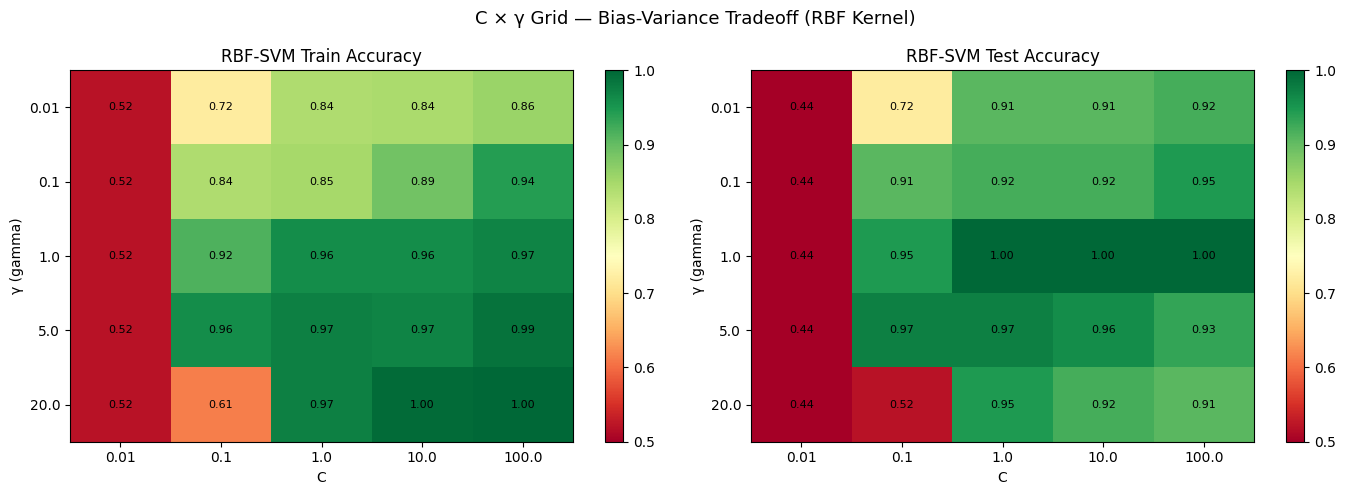

Best test acc: 1.0000  at C=1.0, γ=1.0


In [12]:
from sklearn.model_selection import cross_val_score

X_cg, y_cg = make_moons(n_samples=300, noise=0.2, random_state=42)
sc_cg = StandardScaler()
X_cg_s = sc_cg.fit_transform(X_cg)
Xtr_cg, Xte_cg, ytr_cg, yte_cg = train_test_split(X_cg_s, y_cg, test_size=0.25, random_state=42)

C_grid     = [0.01, 0.1, 1.0, 10.0, 100.0]
gamma_grid = [0.01, 0.1, 1.0, 5.0, 20.0]

train_heat = np.zeros((len(gamma_grid), len(C_grid)))
test_heat  = np.zeros_like(train_heat)

for i, g in enumerate(gamma_grid):
    for j, c in enumerate(C_grid):
        clf = SVC(kernel='rbf', C=c, gamma=g)
        clf.fit(Xtr_cg, ytr_cg)
        train_heat[i, j] = accuracy_score(ytr_cg, clf.predict(Xtr_cg))
        test_heat[i, j]  = accuracy_score(yte_cg, clf.predict(Xte_cg))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, grid, title in zip(axes,
                            [train_heat, test_heat],
                            ['Train Accuracy', 'Test Accuracy']):
    im = ax.imshow(grid, cmap='RdYlGn', vmin=0.5, vmax=1.0, aspect='auto')
    ax.set_xticks(range(len(C_grid))); ax.set_xticklabels(C_grid)
    ax.set_yticks(range(len(gamma_grid))); ax.set_yticklabels(gamma_grid)
    ax.set_xlabel('C'); ax.set_ylabel('\u03b3 (gamma)')
    ax.set_title(f'RBF-SVM {title}')
    plt.colorbar(im, ax=ax)
    for i in range(len(gamma_grid)):
        for j in range(len(C_grid)):
            ax.text(j, i, f'{grid[i,j]:.2f}', ha='center', va='center',
                    fontsize=8, color='black')

plt.suptitle('C \u00d7 \u03b3 Grid — Bias-Variance Tradeoff (RBF Kernel)', fontsize=13)
plt.tight_layout()
plt.show()

bi, bj = np.unravel_index(test_heat.argmax(), test_heat.shape)
print(f"Best test acc: {test_heat[bi,bj]:.4f}  at C={C_grid[bj]}, \u03b3={gamma_grid[bi]}")

<a id="svr"></a>
## 11. SVM for Regression (SVR)

SVR extends SVMs to regression by introducing an **$\varepsilon$-insensitive tube** around predictions. Points within the tube incur zero loss.

### $\varepsilon$-Insensitive Loss

$$L_\varepsilon(y, f(x)) = \max\!\bigl(0,\; |y - f(x)| - \varepsilon\bigr)$$

### Primal Problem

$$\min_{w,b,\xi,\xi^*} \; \frac{1}{2}\|w\|^2 + C\sum_i (\xi_i + \xi_i^*)$$

$$\text{subject to:} \quad y_i - f(x_i) \leq \varepsilon + \xi_i, \quad f(x_i) - y_i \leq \varepsilon + \xi_i^*, \quad \xi_i, \xi_i^* \geq 0$$

where $\xi_i$ and $\xi_i^*$ are slack variables for points above and below the tube.

| Hyperparameter | Effect |
|---|---|
| **C** | Penalty for points outside the tube — same tradeoff as classification |
| **\u03b5** | Tube width: larger \u03b5 → fewer support vectors, smoother fit |
| **kernel** | Same kernels as classification SVM |

**Prediction** (same dual structure):

$$f(x) = \sum_i (\alpha_i - \alpha_i^*) K(x_i, x) + b$$

Fit sklearn `SVR` with RBF kernel on a 1D sine dataset at different values of $\varepsilon$ and $C$. Visualize the $\varepsilon$-tube around the prediction and show how the tube width and penalty control the fit.

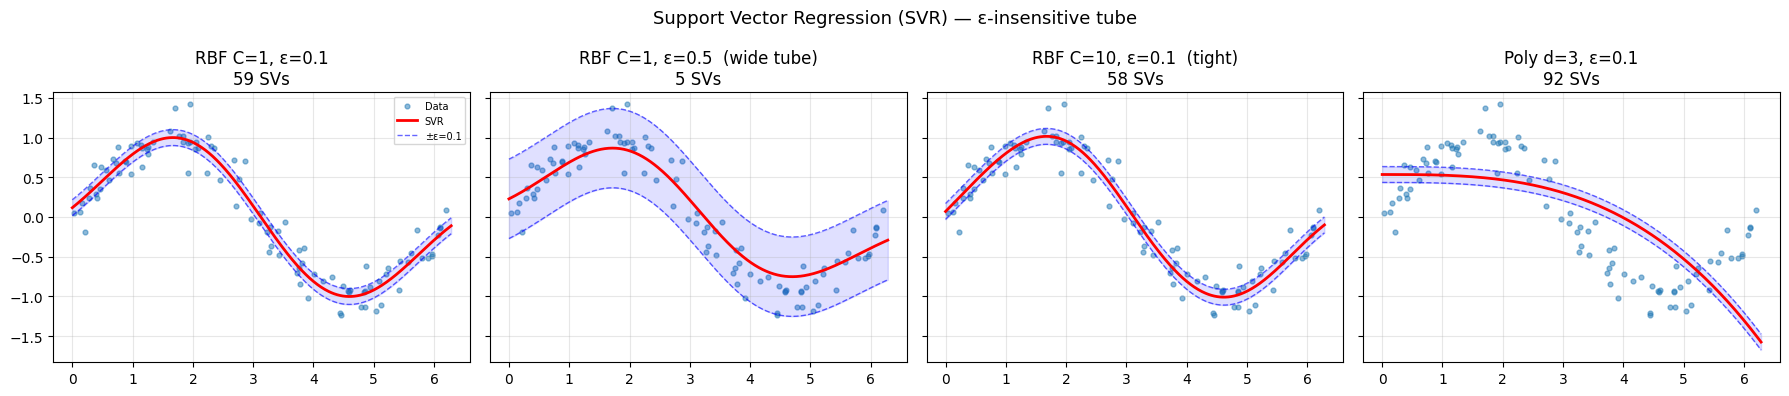

In [13]:
np.random.seed(42)
Xr = np.sort(np.random.uniform(0, 2*np.pi, 100)).reshape(-1, 1)
yr = np.sin(Xr.ravel()) + np.random.normal(0, 0.2, 100)
Xplot = np.linspace(0, 2*np.pi, 400).reshape(-1, 1)

svr_configs = [
    (1.0,  0.1,  'RBF C=1, \u03b5=0.1'),
    (1.0,  0.5,  'RBF C=1, \u03b5=0.5  (wide tube)'),
    (10.0, 0.1,  'RBF C=10, \u03b5=0.1  (tight)'),
    (1.0,  0.1,  'Poly d=3, \u03b5=0.1'),
]
kernels_svr = ['rbf', 'rbf', 'rbf', 'poly']

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, (C, eps, label), kernel in zip(axes, svr_configs, kernels_svr):
    svr = SVR(kernel=kernel, C=C, epsilon=eps, gamma='scale', degree=3)
    svr.fit(Xr, yr)
    yp = svr.predict(Xplot)
    ax.scatter(Xr, yr, s=12, alpha=0.5, label='Data')
    ax.plot(Xplot, yp, 'r-', lw=2, label='SVR')
    ax.plot(Xplot, yp + eps, 'b--', lw=1, alpha=0.6, label=f'\u00b1\u03b5={eps}')
    ax.plot(Xplot, yp - eps, 'b--', lw=1, alpha=0.6)
    ax.fill_between(Xplot.ravel(), yp - eps, yp + eps, alpha=0.12, color='blue')
    ax.set_title(f'{label}\n{svr.support_vectors_.shape[0]} SVs')
    if ax == axes[0]:
        ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

plt.suptitle('Support Vector Regression (SVR) — \u03b5-insensitive tube', fontsize=13)
plt.tight_layout()
plt.show()

<a id="multiclass"></a>
## 12. Multi-class SVM

SVMs are inherently binary. For $K > 2$ classes, two standard decomposition strategies are used.

<a id="ovo"></a>
### 12.1 One-vs-One (OvO)

Train $\binom{K}{2} = K(K-1)/2$ binary classifiers, one per class pair $(k_1, k_2)$. At prediction time, each classifier votes; the class with the most votes wins.

$$\hat{y} = \arg\max_k \sum_{j \neq k} \mathbf{1}[h_{(k,j)}(x) = k]$$

- **Pros:** each sub-problem uses only $\sim 2n/K$ samples — fast even for large $K$
- **Cons:** $O(K^2)$ classifiers to store and evaluate at test time
- **sklearn default:** `SVC` uses OvO internally

<a id="ovr"></a>
### 12.2 One-vs-Rest (OvR)

Train $K$ binary classifiers, each separating class $k$ from all others. At prediction time, return the class whose classifier outputs the highest decision score.

$$\hat{y} = \arg\max_k f_k(x)$$

- **Pros:** only $K$ classifiers
- **Cons:** class imbalance ($n/K$ positives vs $(K-1)n/K$ negatives); ambiguous regions

Implement `OvOClassifier`: train one `KernelSVM` per class pair, then at prediction time count votes across all classifiers and return the majority class.

In [14]:
class OvOClassifier:
    # One-vs-One multi-class wrapper.
    # base_clf_fn: callable that returns a fresh binary classifier

    def __init__(self, base_clf_fn):
        self.base_clf_fn = base_clf_fn

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.clfs_ = {}
        for c1, c2 in combinations(self.classes_, 2):
            mask = (y == c1) | (y == c2)
            clf = self.base_clf_fn()
            clf.fit(X[mask], y[mask])
            self.clfs_[(c1, c2)] = clf
        return self

    def predict(self, X):
        votes = np.zeros((len(X), len(self.classes_)))
        idx_map = {c: i for i, c in enumerate(self.classes_)}
        for (c1, c2), clf in self.clfs_.items():
            preds = clf.predict(X)
            for j, p in enumerate(preds):
                votes[j, idx_map[p]] += 1
        return self.classes_[np.argmax(votes, axis=1)]


print("OvOClassifier defined.")

OvOClassifier defined.


Implement `OvRClassifier`: train one `KernelSVM` per class (class $k$ vs. all others, label map $k \to +1$, rest $\to -1$). At prediction, return the class with the highest decision score.

In [15]:
class OvRClassifier:
    # One-vs-Rest multi-class wrapper.
    # base_clf_fn: callable that returns a fresh binary classifier

    def __init__(self, base_clf_fn):
        self.base_clf_fn = base_clf_fn

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.clfs_ = {}
        for c in self.classes_:
            y_bin = np.where(y == c, c, -1)   # c vs. rest
            clf = self.base_clf_fn()
            clf.fit(X, y_bin)
            self.clfs_[c] = clf
        return self

    def predict(self, X):
        scores = np.column_stack([
            clf.decision_function(X) for clf in self.clfs_.values()
        ])
        return self.classes_[np.argmax(scores, axis=1)]


print("OvRClassifier defined.")

OvRClassifier defined.


<a id="multiclass-demo"></a>
### 12.3 Multi-class Demo

Test `OvOClassifier` and `OvRClassifier` wrapping `KernelSVM(rbf)` on the Iris dataset (3 classes, 4 features). Compare accuracy against sklearn's `SVC` with both OvO and OvR strategies.

In [16]:
iris = load_iris()
Xi, yi = iris.data, iris.target
sc_i = StandardScaler()
Xi_s = sc_i.fit_transform(Xi)
Xtr_i, Xte_i, ytr_i, yte_i = train_test_split(Xi_s, yi, test_size=0.25, random_state=42)

def make_ksvm():
    return KernelSVM(C=5.0, kernel='rbf', gamma=0.5)

ovo = OvOClassifier(make_ksvm)
ovo.fit(Xtr_i, ytr_i)
print(f"Our OvO (KernelSVM)   — test acc: {accuracy_score(yte_i, ovo.predict(Xte_i)):.4f}")

ovr = OvRClassifier(make_ksvm)
ovr.fit(Xtr_i, ytr_i)
print(f"Our OvR (KernelSVM)   — test acc: {accuracy_score(yte_i, ovr.predict(Xte_i)):.4f}")

sk_ovo = SVC(kernel='rbf', C=5.0, gamma=0.5, decision_function_shape='ovo')
sk_ovo.fit(Xtr_i, ytr_i)
print(f"sklearn SVC (OvO)     — test acc: {accuracy_score(yte_i, sk_ovo.predict(Xte_i)):.4f}")

sk_ovr = SVC(kernel='rbf', C=5.0, gamma=0.5, decision_function_shape='ovr')
sk_ovr.fit(Xtr_i, ytr_i)
print(f"sklearn SVC (OvR)     — test acc: {accuracy_score(yte_i, sk_ovr.predict(Xte_i)):.4f}")

Our OvO (KernelSVM)   — test acc: 1.0000
Our OvR (KernelSVM)   — test acc: 1.0000
sklearn SVC (OvO)     — test acc: 1.0000
sklearn SVC (OvR)     — test acc: 1.0000


<a id="pros-cons"></a>
## 13. Pros and Cons

### Advantages

| Property | Detail |
|---|---|
| **Effective in high dimensions** | Works well when $p \gg n$ (e.g., text, genomics) |
| **Kernel flexibility** | Non-linear boundaries without explicit feature engineering |
| **Sparse solution** | Only support vectors determine the model — compact representation |
| **Theoretically grounded** | Margin maximization has strong generalization bounds (VC theory) |
| **Global optimum** | QP is convex — no local minima |

### Disadvantages

| Property | Detail |
|---|---|
| **Slow on large data** | $O(n^2)$–$O(n^3)$ kernel computation — impractical for $n > 10^5$ |
| **Requires feature scaling** | Distances are scale-dependent; always apply `StandardScaler` |
| **No probability output** | Raw output is a score; Platt scaling can add probabilities at a cost |
| **Kernel/hyperparameter selection** | Requires cross-validation; no closed-form guidance |
| **Multi-class overhead** | OvO needs $K(K-1)/2$ classifiers |

### When to Use SVMs

| Situation | Recommended |
|---|---|
| Small-to-medium dataset, non-linear | RBF-kernel SVC |
| High-dimensional sparse (text, gene) | `LinearSVC` |
| Need fast large-scale linear SVM | `SGDClassifier(loss='hinge')` |
| Need probability estimates | Logistic regression or calibrated SVM |

<a id="summary"></a>
## 14. Summary

```
SVM
│
├── Hard-Margin SVM (linearly separable)
│   ├── Maximize margin 2/||w||  ↔  Minimize (1/2)||w||²
│   ├── Constraint: y_i(w·x_i + b) ≥ 1  ∀ i
│   └── Support vectors: points where constraint is active (α_i > 0)
│
├── Soft-Margin SVM (non-separable)
│   ├── Slack variables ξ_i ≥ 0 allow margin violations
│   ├── Objective: (1/2)||w||² + C·Σ ξ_i
│   ├── ξ_i = max(0, 1 - y_i(w·x_i + b))  at optimum = hinge loss
│   └── C: large → tight margin,  small → wide margin
│
├── Kernel Trick (non-linear boundaries)
│   ├── Replace x_i·x_j → K(x_i, x_j) in the dual
│   ├── Implicit feature map φ: K(x,z) = ⟨φ(x), φ(z)⟩
│   ├── Valid kernels: Mercer's theorem (kernel matrix PSD)
│   └── Common: Linear, Polynomial, RBF (most popular), Sigmoid
│
├── Dual Formulation
│   ├── Variables: α_i per training point
│   ├── Constraints: Σ α_i y_i = 0,  0 ≤ α_i ≤ C
│   ├── Prediction: sign(Σ α_i y_i K(x_i, x) + b)
│   └── SMO: efficient O(n²) solver for the dual QP
│
├── SVR (Regression)
│   ├── ε-insensitive tube: loss = 0 inside, linear outside
│   └── Parameters: C (penalty strength), ε (tube width)
│
└── Multi-class
    ├── OvO: K(K-1)/2 classifiers, majority vote  [sklearn default]
    └── OvR: K classifiers, argmax of decision scores
```

### Key Formulas

| Quantity | Formula |
|---|---|
| Margin width | $2\,/\,\|w\|$ |
| Primal objective (soft) | $\min\;\tfrac{1}{2}\|w\|^2 + C\sum_i\max(0,\,1-y_i f(x_i))$ |
| Dual objective | $\max_\alpha\;\sum_i\alpha_i - \tfrac{1}{2}\sum_{ij}\alpha_i\alpha_j y_i y_j K(x_i,x_j)$ |
| Decision function | $f(x) = \sum_i \alpha_i y_i K(x_i, x) + b$ |
| RBF kernel | $K(x,z) = \exp\!\bigl(-\gamma\|x-z\|^2\bigr)$ |
| Hinge loss | $\ell(y,f) = \max(0,\,1-y\cdot f)$ |

<a id="sources"></a>
## 15. Sources

### Foundational Papers
- **Vapnik, V.N. & Chervonenkis, A.Y. (1964)**. On a class of algorithms for pattern recognition. *Avtomatika i Telemekhanika*, 25(6). — Original VC theory.
- **Boser, B.E., Guyon, I.M. & Vapnik, V.N. (1992)**. A training algorithm for optimal margin classifiers. *COLT 1992*, pp. 144–152. — Introduced the kernel trick for SVMs. [DOI](https://doi.org/10.1145/130385.130401)
- **Cortes, C. & Vapnik, V. (1995)**. Support-Vector Networks. *Machine Learning*, 20(3), 273–297. — Soft-margin SVM. [DOI](https://doi.org/10.1007/BF00994018)
- **Platt, J.C. (1998)**. Sequential Minimal Optimization: A Fast Algorithm for Training Support Vector Machines. *Microsoft Research Technical Report MSR-TR-98-14*. — SMO algorithm. [PDF](https://www.microsoft.com/en-us/research/publication/sequential-minimal-optimization-a-fast-algorithm-for-training-support-vector-machines/)
- **Vapnik, V. (1995)**. *The Nature of Statistical Learning Theory*. Springer. — ε-SVR and comprehensive SVM theory.
- **Shalev-Shwartz, S., Singer, Y., Srebro, N. & Cotter, A. (2011)**. Pegasos: Primal Estimated sub-GrAdient SOlver for SVM. *Mathematical Programming*, 127(1), 3–30. — Subgradient method for linear SVMs. [DOI](https://doi.org/10.1007/s10107-010-0420-4)
- **Chang, C.-C. & Lin, C.-J. (2011)**. LIBSVM: A library for support vector machines. *ACM TIST*, 2(3), 27. — The library behind sklearn's SVC. [Link](https://www.csie.ntu.edu.tw/~cjlin/libsvm/)

### Textbooks
- James, Witten, Hastie, Tibshirani. ***An Introduction to Statistical Learning***, 2nd ed. Chapter 9: Support Vector Machines. [Free PDF](https://www.statlearning.com/)
- Hastie, Tibshirani, Friedman. ***The Elements of Statistical Learning***. Chapter 12: Support Vector Machines and Flexible Discriminants. [Free PDF](https://web.stanford.edu/~hastie/ElemStatLearn/)
- Bishop, C.M. ***Pattern Recognition and Machine Learning***. Chapter 7: Sparse Kernel Machines.

### Online Resources
- [scikit-learn — SVM User Guide](https://scikit-learn.org/stable/modules/svm.html)
- [CS229 (Andrew Ng) — SVM Lecture Notes](https://cs229.stanford.edu/notes2022fall/cs229-notes3.pdf)
- [Wikipedia — Support Vector Machine](https://en.wikipedia.org/wiki/Support_vector_machine)
- [Wikipedia — Kernel Method](https://en.wikipedia.org/wiki/Kernel_method)
- [Wikipedia — Sequential Minimal Optimization](https://en.wikipedia.org/wiki/Sequential_minimal_optimization)
- [Wikipedia — Mercer's Theorem](https://en.wikipedia.org/wiki/Mercer%27s_theorem)